# Blackjack DQN 完整實驗流程

本 notebook 依序執行整個研究流程，請在**專案根目錄**（含 `blackjack_rl/` 的資料夾）開啟。

| 階段 | 內容 | 預估時間 |
|---|---|---|
| 0 | 單元測試、basic strategy 基準 | 5 分鐘 |
| 1 | 基準表：basic、DP、隨機策略（多個獨立 seed） | 約 1.5~2 小時 |
| 2 | DP 蒸餾出牌頭（每個訓練 seed 各一份示範） | 15~20 分鐘 |
| 3 | 開發 seed 快速檢查 | 5 分鐘 |
| 4 | 出牌最終驗證（配對評估） | 約 45 分鐘 |
| 5 | 凍結出牌頭、訓練下注頭 | 15~30 分鐘 |
| 6 | 線性下注對照 | 約 20 分鐘 |
| 6b | 下注模型驗證：校準、同序列下注效果 | 約 30 分鐘 |
| 7 | 完整系統最終評估 | 約 4~5 小時 |
| 8 | 消融實驗（選用） | 1~2 小時 |
| 9 | 資金管理：結局、期末資金、回撤、敏感度、訓練 vs 測試 | 約 2~3 小時 |

**使用方式**

- 由上而下執行。每個評估結果都會存成 `results/*.json`，重跑儲存格時直接讀取，不會重算；要重算請把對應的 `refresh=False` 改成 `True`
- 訓練以子程序執行，紀錄在 `logs/`，模型在 `runs/`；已完成的訓練會自動略過
- 第一次使用建議先把下一格的 `QUICK` 設為 `True`，用極小參數跑完整份 notebook（約 5 分鐘），確認環境沒有問題。QUICK 模式的輸出放在 `runs_quick/`、`results_quick/`，不會影響正式結果，數值本身沒有意義

## 設定

In [1]:
QUICK = False          # True：極小參數快速跑完全部流程，只用來確認環境

DECKS = "4-8"          # 副數隨機，確保 state 不隱含剩餘張數
SHOE = "seen_counts"   # state 包含各點數已出現張數
TRAIN_SEEDS = [1, 2, 3]            # 訓練 seed：驗證方法的穩定性
DEV_SEED = 777                     # 開發 seed：只用來檢查
TEST_SEEDS = [2027, 2028, 2029]    # 測試 seed：只在最終驗證使用
DP_ROUNDS = 200_000                # 每個訓練 seed 的 DP 示範局數
DISTILL_UPDATES = 20_000
BET_STEPS = 5_000_000              # 下注頭訓練步數（約 200 萬局）
BET_LINEAR_ROUNDS = 2_000_000      # 線性下注對照的局數
DEV_ROUNDS = 100_000
FINAL_ROUNDS = 1_000_000
BASE_ROUNDS = 1_000_000            # 基準表：basic strategy 的局數
BASE_DP_ROUNDS = 300_000           # 基準表：DP 絕對期望值的局數（DP 較慢）
BASE_PAIRED_ROUNDS = 1_000_000     # 基準表：DP 相對 basic 的配對評估局數
BASE_RANDOM_ROUNDS = 100_000
BET_CALIB_ROUNDS = 1_000_000       # 下注模型驗證：獨立測試牌局（校準用）
BET_SEQ_ROUNDS = 1_000_000         # 下注模型驗證：錄製序列（同序列下注效果）
ABL_STEPS = 2_000_000              # 消融實驗的 RL 訓練步數
ABL_ROUNDS = 300_000               # 消融實驗的評估局數
# 第 9 階段：資金管理（期限內翻倍）
BANK_START, BANK_TARGET, BANK_HORIZON = 50, 100, 500
BANK_BETS = "1,2,4,8,16"
BANK_TRAIN_ROUNDS = 3_000_000      # 錄製的訓練序列局數
BANK_TEST_ROUNDS = 10_000_000      # 錄製的測試序列局數（不同 seed）；不重疊 episode 數 = 局數 / 期限
BANK_GRID_STARTS = [25, 50, 75]    # 敏感度網格：起始資金（目標固定為 BANK_TARGET）
BANK_GRID_HORIZONS = [250, 500, 1000]   # 敏感度網格：期限；DQN 與 DP 以最長期限訓練／求解
BANK_EPISODES = 1_000_000          # DQN 訓練的 episode 數
BANK_EVAL_EPISODES = None          # 最終評估的 episode 上限（None = 用完測試序列的所有不重疊區段）
WORKERS = 3                        # 同時執行的評估行程數（依 CPU 核心調整）
PARALLEL = True                    # 不同訓練 seed 的訓練是否平行

EXTRA = []                         # QUICK 模式額外參數
if QUICK:
    TRAIN_SEEDS, TEST_SEEDS = [1], [2027]
    DP_ROUNDS, DISTILL_UPDATES = 300, 50
    BET_STEPS, BET_LINEAR_ROUNDS = 2000, 300
    DEV_ROUNDS = FINAL_ROUNDS = ABL_ROUNDS = 300
    BASE_ROUNDS, BASE_DP_ROUNDS, BASE_PAIRED_ROUNDS, BASE_RANDOM_ROUNDS = 2000, 200, 200, 200
    BET_CALIB_ROUNDS, BET_SEQ_ROUNDS = 3000, 3000
    ABL_STEPS = 3200
    EXTRA = ["--eval-rounds", "100"]
    BANK_START, BANK_TARGET, BANK_HORIZON, BANK_BETS = 10, 20, 40, "1,2,4,8"
    BANK_TRAIN_ROUNDS, BANK_TEST_ROUNDS = 3000, 3000
    BANK_EPISODES = 2000
    BANK_GRID_STARTS, BANK_GRID_HORIZONS = [5, 10, 15], [20, 40]

In [2]:
import os, sys, json, subprocess
import numpy as np
assert os.path.isdir("blackjack_rl"), "請在專案根目錄開啟這個 notebook"

RUNS = "runs_quick" if QUICK else "runs"
RES = "results_quick" if QUICK else "results"
LOGS = "logs_quick" if QUICK else "logs"
for d in (RUNS, RES, LOGS):
    os.makedirs(d, exist_ok=True)

from blackjack_rl.notebook_utils import run_commands, tail, cached, paired_many, pool, fmt_pct, full_system_many
from blackjack_rl.config import RuleConfig, ObsConfig

RULE_KW = {"n_decks": tuple(int(x) for x in DECKS.split("-")) if "-" in DECKS else int(DECKS)}
try:
    import matplotlib.pyplot as plt
    from matplotlib import font_manager
    HAS_PLT = True
    # 尋找可顯示中文的字型；找不到時圖表改用英文標籤
    _cjk = ["Microsoft JhengHei", "Noto Sans CJK TC", "Noto Sans TC", "PingFang TC", "Heiti TC",
            "Noto Sans CJK SC", "Microsoft YaHei", "WenQuanYi Zen Hei", "SimHei", "Arial Unicode MS"]
    _have = {f.name for f in font_manager.fontManager.ttflist}
    _font = next((f for f in _cjk if f in _have), None)
    if _font:
        plt.rcParams["font.sans-serif"] = [_font] + plt.rcParams["font.sans-serif"]
    plt.rcParams["axes.unicode_minus"] = False
    def L(zh, en):
        return zh if _font else en
    print("圖表字型：" + (_font or "未找到中文字型，圖表使用英文標籤"))
except ImportError:
    HAS_PLT = False
    print("未安裝 matplotlib，將略過圖表")

def todo(paths):
    return [p for p in paths if not os.path.exists(p)]

print(f"模式：{'QUICK（僅測試環境）' if QUICK else '正式'}；輸出：{RUNS}/、{RES}/、{LOGS}/")

圖表字型：未找到中文字型，圖表使用英文標籤
模式：正式；輸出：runs/、results/、logs/


## 第 0 階段：環境檢查

單元測試應全部通過；basic strategy 的每單位下注期望值應約在 -0.3%~-0.6%。

In [3]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "tests"], capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])

from blackjack_rl.evaluate import evaluate_policy
from blackjack_rl.strategies import BasicStrategy
def _basic():
    res = evaluate_policy(BasicStrategy(), RuleConfig(**RULE_KW), ObsConfig(SHOE),
                          300 if QUICK else 2_000_000, seed=12345)
    return {"ev": float(res["ev_per_unit_bet"]), "ci95": [float(x) for x in res["ci95"]]}
basic = cached(f"{RES}/stage0_basic.json", _basic)
print("basic strategy 每單位下注 EV：", fmt_pct(basic["ev"], basic["ci95"]))

98 passed in 127.87s (0:02:07)
已計算並存檔：results/stage0_basic.json（2.4 分鐘）
basic strategy 每單位下注 EV： -0.394% [-0.552%, -0.236%]


## 第 1 階段：基準表（basic、DP、隨機策略，多個獨立 seed）

每個測試 seed 各自評估，再合併：
- **絕對期望值**：以實際輸贏、固定最小注打 n 局的每單位下注報酬
- **DP − basic（配對）**：同一牌序上兩者各打一次、只記錄報酬差（期望結算），雜訊小很多

DP 出牌只用可見資訊（已出現張數與副數的先驗），是出牌改善的近似上限（見 `optimal.py` 的近似說明）。合併結果中若「seed 間標準差」與「單次標準誤」相近，代表各 seed 的差異只是抽樣雜訊。

In [4]:
from blackjack_rl.baselines import run_baselines, format_baselines
baselines = cached(f"{RES}/stage1_baselines.json", lambda: run_baselines(
    RULE_KW, SHOE, TEST_SEEDS, BASE_ROUNDS, BASE_DP_ROUNDS, BASE_RANDOM_ROUNDS, BASE_PAIRED_ROUNDS, WORKERS))
print(format_baselines(baselines))
_p = baselines["pooled"]["dp_vs_basic"]
dp_ref = {"mean_diff": _p["ev"], "ci95": _p["ci95"],
          "differ_rate": float(np.mean([r["differ_rate"] for r in baselines["per_seed"] if r["policy"] == "dp_vs_basic"]))}

已計算並存檔：results/stage1_baselines.json（85.4 分鐘）
策略                        seed         局數   每單位下注期望值（95% CI）
basic strategy（絕對）        2027  1,000,000   -0.445% [-0.669%, -0.222%]
DP 出牌（絕對）                 2027    300,000   -0.401% [-0.811%, +0.009%]
隨機策略（絕對）                  2027    100,000   -42.962% [-43.699%, -42.225%]
DP − basic（配對）            2027  1,000,000   +0.158% [+0.118%, +0.198%]
basic strategy（絕對）        2028  1,000,000   -0.497% [-0.720%, -0.273%]
DP 出牌（絕對）                 2028    300,000   -0.325% [-0.734%, +0.084%]
隨機策略（絕對）                  2028    100,000   -43.380% [-44.113%, -42.647%]
DP − basic（配對）            2028  1,000,000   +0.160% [+0.120%, +0.200%]
basic strategy（絕對）        2029  1,000,000   -0.287% [-0.510%, -0.063%]
DP 出牌（絕對）                 2029    300,000   +0.018% [-0.391%, +0.428%]
隨機策略（絕對）                  2029    100,000   -42.270% [-43.009%, -41.532%]
DP − basic（配對）            2029  1,000,000   +0.162% [+0.122%, +0.202%]

合併                      seed 數 

## 第 2 階段：DP 蒸餾出牌頭

每個訓練 seed 各自收集一份 DP 示範資料（收集種子 = 訓練 seed + 777），再把各動作的 Q 值回歸到 DP 的期望值。蒸餾最後的 loss 應低於約 0.005。

In [5]:
distill = {s: f"{RUNS}/distill_s{s}/last.pt" for s in TRAIN_SEEDS}
cmds, logs = [], []
for s in TRAIN_SEEDS:
    if os.path.exists(distill[s]):
        continue
    cmds.append(["blackjack_rl.train", "--decks", DECKS, "--no-betting", "--shoe-info", SHOE,
                 "--teacher", "dp", "--pretrain-rounds", DP_ROUNDS, "--pretrain-updates", DISTILL_UPDATES,
                 "--teacher-cache", f"{RUNS}/dp_cache_s{s}.npz", "--steps", 0, "--seed", s,
                 "--out", f"{RUNS}/distill_s{s}"])
    logs.append(f"{LOGS}/stage2_distill_s{s}.txt")
if cmds:
    run_commands(cmds, logs, parallel=PARALLEL)
for s in TRAIN_SEEDS:
    print(f"seed {s}：", end=""); tail(f"{LOGS}/stage2_distill_s{s}.txt", 1, grep="蒸餾")

完成 3 個指令（13.2 分鐘）
seed 1：DP 蒸餾：287,519 個決策、20,000 次更新，最後 loss 0.0023（788s）
seed 2：DP 蒸餾：287,687 個決策、20,000 次更新，最後 loss 0.0022（791s）
seed 3：DP 蒸餾：287,576 個決策、20,000 次更新，最後 loss 0.0023（783s）


## 第 3 階段：開發 seed 快速檢查

只用開發 seed，確認每個蒸餾模型相對 basic 都是正的。若有明顯為負的模型，先檢查該 seed 的蒸餾 loss。

In [6]:
dev = cached(f"{RES}/stage3_dev.json", lambda: paired_many(
    [{"model": distill[s], "seed": DEV_SEED, "rounds": DEV_ROUNDS} for s in TRAIN_SEEDS], WORKERS))
for s, r in zip(TRAIN_SEEDS, dev):
    print(f"distill_s{s}：{fmt_pct(r['mean_diff'], r['ci95'])}；決策不同 {r['differ_rate']:.1%}")

已計算並存檔：results/stage3_dev.json（1.5 分鐘）
distill_s1：+0.113% [-0.008%, +0.235%]；決策不同 6.1%
distill_s2：+0.166% [+0.051%, +0.281%]；決策不同 5.6%
distill_s3：+0.141% [+0.025%, +0.257%]；決策不同 5.7%


## 第 4 階段：出牌最終驗證

每個蒸餾模型在每個測試 seed 上做 100 萬局配對評估。**判定標準（事先訂定）**：全部結果合併後，95% 信賴區間下限大於 0，即為顯著優於 basic strategy。

In [7]:
jobs = [{"model": distill[s], "seed": t, "rounds": FINAL_ROUNDS} for s in TRAIN_SEEDS for t in TEST_SEEDS]
final_play = cached(f"{RES}/stage4_final_play.json", lambda: paired_many(jobs, WORKERS))

print(f"{'模型':<14}{'測試 seed':>10}   相對 basic strategy")
for j, r in zip(jobs, final_play):
    print(f"{os.path.basename(os.path.dirname(j['model'])):<14}{j['seed']:>10}   {fmt_pct(r['mean_diff'], r['ci95'])}")
print()
per_model = {}
for s in TRAIN_SEEDS:
    rs = [r for j, r in zip(jobs, final_play) if j["model"] == distill[s]]
    per_model[s] = pool(rs)
    print(f"distill_s{s} 合併：{fmt_pct(per_model[s]['mean'], per_model[s]['ci95'])}")
overall = pool(final_play)
print(f"\n全部合併（{overall['n']} 次）：{fmt_pct(overall['mean'], overall['ci95'])}  →  "
      + ("顯著優於 basic strategy" if overall["ci95"][0] > 0 else "無法確認優於 basic strategy"))
print(f"達到 DP 改善量的 {overall['mean'] / dp_ref['mean_diff']:.0%}（DP：{fmt_pct(dp_ref['mean_diff'], dp_ref['ci95'])}，"
      f"{len(TEST_SEEDS)} 個 seed 合併；比例的不確定性主要來自 DP 的信賴區間）")

已計算並存檔：results/stage4_final_play.json（45.0 分鐘）
模型               測試 seed   相對 basic strategy
distill_s1          2027   +0.140% [+0.102%, +0.178%]
distill_s1          2028   +0.150% [+0.112%, +0.188%]
distill_s1          2029   +0.170% [+0.132%, +0.208%]
distill_s2          2027   +0.144% [+0.107%, +0.181%]
distill_s2          2028   +0.129% [+0.093%, +0.166%]
distill_s2          2029   +0.160% [+0.124%, +0.197%]
distill_s3          2027   +0.143% [+0.106%, +0.180%]
distill_s3          2028   +0.150% [+0.114%, +0.187%]
distill_s3          2029   +0.170% [+0.133%, +0.207%]

distill_s1 合併：+0.153% [+0.131%, +0.175%]
distill_s2 合併：+0.144% [+0.123%, +0.166%]
distill_s3 合併：+0.155% [+0.133%, +0.176%]

全部合併（9 次）：+0.151% [+0.138%, +0.163%]  →  顯著優於 basic strategy
達到 DP 改善量的 94%（DP：+0.160% [+0.137%, +0.183%]，3 個 seed 合併；比例的不確定性主要來自 DP 的信賴區間）


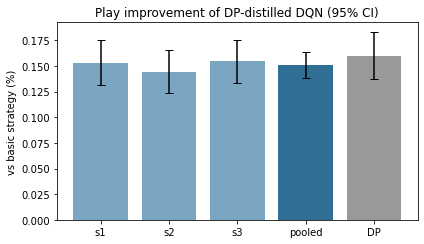

In [8]:
if HAS_PLT:
    names = [f"s{s}" for s in TRAIN_SEEDS] + [L("合併", "pooled"), "DP"]
    vals = [per_model[s]["mean"] for s in TRAIN_SEEDS] + [overall["mean"], dp_ref["mean_diff"]]
    cis = [per_model[s]["ci95"] for s in TRAIN_SEEDS] + [overall["ci95"], dp_ref["ci95"]]
    err = np.array([[v - c[0], c[1] - v] for v, c in zip(vals, cis)]).T * 100
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.bar(range(len(vals)), np.array(vals) * 100, yerr=err, capsize=4,
           color=["#7aa6c2"] * len(TRAIN_SEEDS) + ["#2f6f95", "#999999"])
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(range(len(vals))); ax.set_xticklabels(names)
    ax.set_ylabel(L("相對 basic strategy（%）", "vs basic strategy (%)"))
    ax.set_title(L("DP 蒸餾 DQN 的出牌改善（95% CI）", "Play improvement of DP-distilled DQN (95% CI)"))
    plt.tight_layout(); plt.show()

## 第 5 階段：組合完整系統（凍結出牌頭、訓練下注頭）

從蒸餾模型載入出牌頭並凍結，只訓練下注頭。出牌一律貪婪，所以下注頭學到的是這個出牌策略的實際期望值。訓練紀錄中的 loss 會顯示 nan（沒有 TD 更新），屬正常。

In [9]:
full = {s: f"{RUNS}/full_s{s}/last.pt" for s in TRAIN_SEEDS}
cmds, logs = [], []
for s in TRAIN_SEEDS:
    if os.path.exists(full[s]):
        continue
    cmds.append(["blackjack_rl.train", "--decks", DECKS, "--shoe-info", SHOE,
                 "--init-play", distill[s], "--freeze-play", "--bet-memory", 100_000_000,
                 "--steps", BET_STEPS, "--eval-every", 1_000_000, "--seed", s,
                 "--out", f"{RUNS}/full_s{s}"] + EXTRA)
    logs.append(f"{LOGS}/stage5_full_s{s}.txt")
if cmds:
    run_commands(cmds, logs, parallel=PARALLEL)
print("完成：", list(full.values()))

完成 3 個指令（21.0 分鐘）
完成： ['runs/full_s1/last.pt', 'runs/full_s2/last.pt', 'runs/full_s3/last.pt']


已計算並存檔：results/stage5_bet_tc_s1.json（1.2 分鐘）
已計算並存檔：results/stage5_bet_tc_s2.json（1.2 分鐘）
已計算並存檔：results/stage5_bet_tc_s3.json（1.2 分鐘）


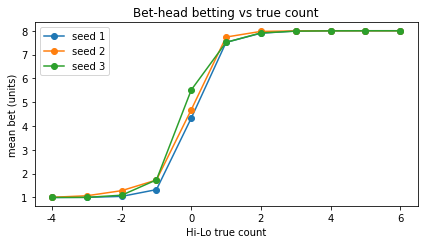

In [10]:
# 下注行為：平均下注應隨 true count 上升（true count 只用於事後分析，從未進入 state）
from blackjack_rl.agent import DQNAgent
from blackjack_rl.analysis import bet_by_true_count
def _bets(s):
    b = bet_by_true_count(DQNAgent.load(full[s]), 500 if QUICK else 100_000, verbose=False)
    return {str(k): v for k, v in b.items()}
bet_tc = {s: cached(f"{RES}/stage5_bet_tc_s{s}.json", lambda s=s: _bets(s)) for s in TRAIN_SEEDS}
if HAS_PLT:
    fig, ax = plt.subplots(figsize=(6, 3.5))
    for s in TRAIN_SEEDS:
        tcs = sorted(int(k) for k in bet_tc[s])
        ax.plot(tcs, [bet_tc[s][str(t)][1] / bet_tc[s][str(t)][0] for t in tcs], marker="o", label=f"seed {s}")
    ax.set_xlabel("Hi-Lo true count"); ax.set_ylabel(L("平均下注倍數", "mean bet (units)"))
    ax.set_title(L("下注頭的下注行為", "Bet-head betting vs true count")); ax.legend()
    plt.tight_layout(); plt.show()

## 第 6 階段：線性下注對照

用相同的出牌策略收集資料訓練線性下注，局數與下注頭看過的局數相近，作為下注頭的比較對象。

In [11]:
cmds, logs = [], []
for s in TRAIN_SEEDS:
    if os.path.exists(f"{RUNS}/full_s{s}/bet_linear.npz"):
        continue
    cmds.append(["blackjack_rl.bet_learn", "--decks", DECKS, "--play", full[s],
                 "--rounds", BET_LINEAR_ROUNDS, "--out", f"{RUNS}/full_s{s}"])
    logs.append(f"{LOGS}/stage6_linear_s{s}.txt")
if cmds:
    run_commands(cmds, logs, parallel=PARALLEL)
for s in TRAIN_SEEDS:
    print(f"seed {s}："); tail(f"{LOGS}/stage6_linear_s{s}.txt", 3)

完成 3 個指令（23.7 分鐘）
seed 1：
神經網路   驗證集 MSE 改善 +0.0157%   預測範圍 [-3.75%, +3.34%]   下最大注比例 28.7%
MSE 改善很小是正常的：單局結果的雜訊遠大於牌堆組成帶來的差異。
兩者實際下注效果請用 compare --matrix 比較。
seed 2：
神經網路   驗證集 MSE 改善 +0.0148%   預測範圍 [-3.09%, +4.33%]   下最大注比例 55.4%
MSE 改善很小是正常的：單局結果的雜訊遠大於牌堆組成帶來的差異。
兩者實際下注效果請用 compare --matrix 比較。
seed 3：
神經網路   驗證集 MSE 改善 +0.0225%   預測範圍 [-3.94%, +4.12%]   下最大注比例 56.2%
MSE 改善很小是正常的：單局結果的雜訊遠大於牌堆組成帶來的差異。
兩者實際下注效果請用 compare --matrix 比較。


## 第 6b 階段：下注模型驗證

分兩部分，兩者都使用**與訓練不同 seed 的獨立牌局**：

1. **預測能力（校準）**：依預測值分成 10 個等機率等級，比較各級的預測平均與實際平均。完美校準時點落在對角線上；校準斜率 < 1 表示預測過度分散（過度自信），> 1 表示太保守；截距反映整體偏差
2. **實際下注效果**：下注不影響發牌，所以所有下注模型在**同一條錄製序列**上計算報酬，差異只來自下注決策。所有模型共用相同的「預測值 → 下注」規則，差別只在預測值。同一副牌內的局彼此相關，信賴區間以 1,000 局為區塊做 bootstrap

In [12]:
cmds, logs = [], []
for s in TRAIN_SEEDS:
    out = f"{RES}/stage6b_bet_eval_s{s}.json"
    if os.path.exists(out):
        continue
    cmds.append(["blackjack_rl.bet_eval", "--decks", DECKS, "--play", full[s],
                 "--linear", f"{RUNS}/full_s{s}/bet_linear.npz", "--net", f"{RUNS}/full_s{s}/bet_net.pt",
                 "--head", full[s], "--calib-rounds", BET_CALIB_ROUNDS, "--calib-seed", 3033 + s,
                 "--seq-rounds", BET_SEQ_ROUNDS, "--seq-seed", 4044 + s, "--json", out])
    logs.append(f"{LOGS}/stage6b_bet_eval_s{s}.txt")
if cmds:
    run_commands(cmds, logs, parallel=PARALLEL)
from blackjack_rl.bet_eval import format_report
bet_eval = {s: json.load(open(f"{RES}/stage6b_bet_eval_s{s}.json", encoding="utf-8")) for s in TRAIN_SEEDS}
print(f"（以下為 seed {TRAIN_SEEDS[0]}；其他 seed 的完整報告見 {RES}/stage6b_bet_eval_s*.json）\n")
print(format_report(bet_eval[TRAIN_SEEDS[0]]["calibration"], bet_eval[TRAIN_SEEDS[0]]["betting"]))

完成 3 個指令（19.3 分鐘）
（以下為 seed 1；其他 seed 的完整報告見 results/stage6b_bet_eval_s*.json）

一、預測能力（獨立測試牌局，期望結算）

[線性下注]  平均預測 -0.184%  實際 +0.032%  相關 +0.0130
  校準：實際 = +0.200% + 0.91（±0.14）× 預測    最高等級 − 最低等級 = +3.86%（±0.75%）
  等級   預測平均   實際平均（±1.96 SE）
    1     -2.32%     -1.72%（±0.52%）
    2     -1.37%     -0.81%（±0.52%）
    3     -0.93%     -0.95%（±0.52%）
    4     -0.60%     -0.28%（±0.53%）
    5     -0.34%     -0.18%（±0.52%）
    6     -0.11%     -0.15%（±0.53%）
    7     +0.20%     +0.33%（±0.53%）
    8     +0.56%     +0.56%（±0.53%）
    9     +1.04%     +1.40%（±0.53%）
   10     +2.05%     +2.14%（±0.54%）

[神經網路下注]  平均預測 -0.401%  實際 +0.032%  相關 +0.0122
  校準：實際 = +0.562% + 1.32（±0.21）× 預測    最高等級 − 最低等級 = +3.87%（±0.75%）
  等級   預測平均   實際平均（±1.96 SE）
    1     -1.74%     -1.85%（±0.52%）
    2     -1.14%     -0.73%（±0.52%）
    3     -0.93%     -0.14%（±0.52%）
    4     -0.73%     -0.52%（±0.53%）
    5     -0.54%     -0.30%（±0.52%）
    6     -0.35%     -0.26%（±0.53%）
    7     -0.14%     +0.36%（±0.53%）


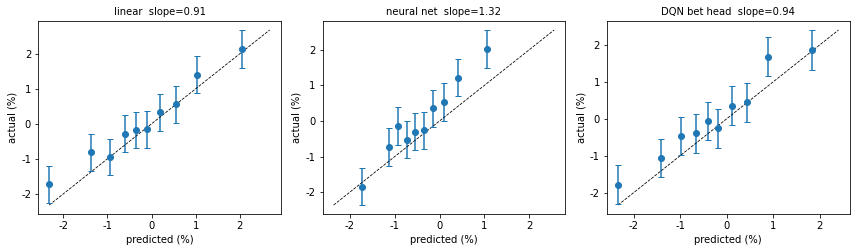

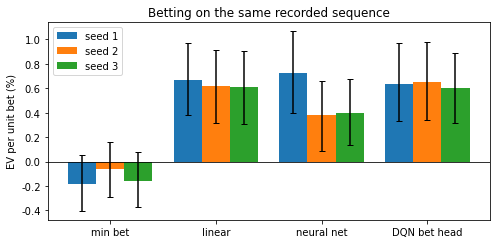

In [13]:
if HAS_PLT:
    ev0 = bet_eval[TRAIN_SEEDS[0]]
    names = list(ev0["calibration"])
    en = {"線性下注": "linear", "神經網路下注": "neural net", "DQN 下注頭": "DQN bet head"}
    fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 3.6), squeeze=False)
    for ax, n in zip(axes[0], names):
        b = ev0["calibration"][n]["bins"]
        x = np.array([t["pred"] for t in b]) * 100; y = np.array([t["actual"] for t in b]) * 100
        e = np.array([t["se"] for t in b]) * 196
        lo, hi = min(x.min(), (y - e).min()), max(x.max(), (y + e).max())
        ax.plot([lo, hi], [lo, hi], "k--", lw=0.8)
        ax.errorbar(x, y, yerr=e, fmt="o", capsize=3)
        c = ev0["calibration"][n]
        ax.set_title(f"{L(n, en.get(n, n))}  slope={c['slope']:.2f}", fontsize=10)
        ax.set_xlabel(L("預測（%）", "predicted (%)")); ax.set_ylabel(L("實際（%）", "actual (%)"))
    plt.tight_layout(); plt.show()

    # 各 seed 的下注效果：每單位下注 EV（區塊 bootstrap 95% CI）
    strat = [k for k in bet_eval[TRAIN_SEEDS[0]]["betting"] if not k.startswith("_")]
    fig, ax = plt.subplots(figsize=(7, 3.5))
    w = 0.8 / len(TRAIN_SEEDS)
    for i, s in enumerate(TRAIN_SEEDS):
        bt = bet_eval[s]["betting"]
        v = np.array([bt[k]["ev_per_unit"] for k in strat]) * 100
        err = np.array([[bt[k]["ev_per_unit"] - bt[k]["ev_per_unit_ci95"][0],
                         bt[k]["ev_per_unit_ci95"][1] - bt[k]["ev_per_unit"]] for k in strat]).T * 100
        ax.bar(np.arange(len(strat)) + i * w, v, w, yerr=err, capsize=3, label=f"seed {s}")
    ax.axhline(0, color="k", lw=0.8)
    en2 = {"最小注": "min bet", **en}
    ax.set_xticks(np.arange(len(strat)) + w * (len(TRAIN_SEEDS) - 1) / 2)
    ax.set_xticklabels([L(k, en2.get(k, k)) for k in strat])
    ax.set_ylabel(L("每單位下注 EV（%）", "EV per unit bet (%)"))
    ax.set_title(L("同一條錄製序列上的下注效果", "Betting on the same recorded sequence")); ax.legend()
    plt.tight_layout(); plt.show()

## 第 7 階段：完整系統最終評估

每個完整系統在每個測試 seed 上評估 6 種組合（出牌：basic／DQN × 下注：最小注／線性／DQN 下注頭）。**判定標準**：「DQN 出牌 + DQN 下注頭」的每局報酬合併後，95% 信賴區間下限大於 0，即為正期望值。這一步最耗時。

In [14]:
fjobs = [{"model": full[s], "bet_linear": f"{RUNS}/full_s{s}/bet_linear.npz", "seed": t, "rounds": FINAL_ROUNDS}
         for s in TRAIN_SEEDS for t in TEST_SEEDS]
final_full = cached(f"{RES}/stage7_final_full.json", lambda: full_system_many(fjobs, WORKERS))

cells = ["basic+min", "basic+linear", "basic+head", "dqn+min", "dqn+linear", "dqn+head"]
label = {"basic+min": "basic 出牌 + 最小注", "basic+linear": "basic 出牌 + 線性下注",
         "basic+head": "basic 出牌 + DQN 下注頭", "dqn+min": "DQN 出牌 + 最小注",
         "dqn+linear": "DQN 出牌 + 線性下注", "dqn+head": "DQN 出牌 + DQN 下注頭（完整系統）"}
print(f"{'組合':<30}{'每單位下注 EV':>14}{'平均下注':>10}   每局報酬（合併 95% CI）")
summary = {}
for c in cells:
    evs = [r["cells"][c]["ev_per_unit"] for r in final_full]
    bets = [r["cells"][c]["mean_bet"] for r in final_full]
    rr = pool([{"mean_diff": r["cells"][c]["round_mean"], "ci95": r["cells"][c]["round_ci95"]} for r in final_full])
    summary[c] = {"ev": float(np.mean(evs)), "bet": float(np.mean(bets)), "round": rr}
    print(f"{label[c]:<30}{np.mean(evs) * 100:>+13.3f}%{np.mean(bets):>10.2f}   {fmt_pct(rr['mean'], rr['ci95'])}")
ok = summary["dqn+head"]["round"]["ci95"][0] > 0
print("\n完整系統：" + ("顯著正期望值" if ok else "無法確認為正期望值"))

已計算並存檔：results/stage7_final_full.json（107.5 分鐘）
組合                                  每單位下注 EV      平均下注   每局報酬（合併 95% CI）
basic 出牌 + 最小注                       -0.410%      1.00   -0.410% [-0.484%, -0.335%]
basic 出牌 + 線性下注                      +0.423%      3.92   +1.658% [+1.272%, +2.043%]
basic 出牌 + DQN 下注頭                   +0.388%      3.93   +1.524% [+1.138%, +1.911%]
DQN 出牌 + 最小注                         -0.217%      1.00   -0.217% [-0.292%, -0.142%]
DQN 出牌 + 線性下注                        +0.592%      3.94   +2.329% [+1.938%, +2.720%]
DQN 出牌 + DQN 下注頭（完整系統）               +0.561%      3.95   +2.215% [+1.822%, +2.607%]

完整系統：顯著正期望值


## 第 8 階段：消融實驗（選用）

用訓練 seed 1 訓練四個對照模型，與蒸餾模型一起在第一個測試 seed 上評估，說明各設計的必要性：

- **從零訓練**：不用任何老師
- **模仿 basic + RL**：以 basic strategy 為起點
- **DP 蒸餾 + RL 微調**：蒸餾後再以 RL 微調（λ = 0.1）
- **無牌堆資訊的 DP 蒸餾**：state 不含已出現張數，檢驗牌堆資訊本身的價值

In [15]:
s1 = TRAIN_SEEDS[0]
common = ["--decks", DECKS, "--no-betting", "--lr", "1e-4", "--lr-end", "1e-5"]
rl = ["--steps", ABL_STEPS, "--eps-decay", max(ABL_STEPS // 2, 1), "--eval-every", ABL_STEPS] + EXTRA
if QUICK:
    rl += ["--learning-starts", 300]
abl = {
    "從零訓練": (["--shoe-info", SHOE] + rl, "abl_scratch"),
    "模仿 basic + RL": (["--shoe-info", SHOE, "--pretrain-rounds", DP_ROUNDS, "--pretrain-updates",
                        DISTILL_UPDATES // 2, "--eps-start", 0.1] + rl, "abl_imit_basic"),
    "DP 蒸餾 + RL 微調": (["--shoe-info", SHOE, "--teacher", "dp", "--pretrain-rounds", DP_ROUNDS,
                         "--pretrain-updates", DISTILL_UPDATES, "--teacher-cache", f"{RUNS}/dp_cache_s{s1}.npz",
                         "--anchor-weight", 0.1, "--eps-start", 0.1] + rl, "abl_dp_rl"),
    "無牌堆資訊的 DP 蒸餾": (["--shoe-info", "none", "--teacher", "dp", "--pretrain-rounds", DP_ROUNDS,
                           "--pretrain-updates", DISTILL_UPDATES, "--teacher-cache",
                           f"{RUNS}/dp_cache_none_s{s1}.npz", "--steps", 0], "abl_dp_noshoe"),
}
cmds, logs = [], []
for name, (args, out) in abl.items():
    if os.path.exists(f"{RUNS}/{out}/last.pt"):
        continue
    cmds.append(["blackjack_rl.train"] + common + args + ["--seed", s1, "--out", f"{RUNS}/{out}"])
    logs.append(f"{LOGS}/abl_{out}.txt")
if cmds:
    run_commands(cmds, logs, parallel=True)

models = {**{n: f"{RUNS}/{o}/last.pt" for n, (_, o) in abl.items()}, "DP 蒸餾（主方法）": distill[s1]}
abl_res = cached(f"{RES}/stage8_ablation.json", lambda: paired_many(
    [{"model": m, "seed": TEST_SEEDS[0], "rounds": ABL_ROUNDS} for m in models.values()], WORKERS))
for (n, _), r in zip(models.items(), abl_res):
    print(f"{n:<16} 相對 basic：{fmt_pct(r['mean_diff'], r['ci95'])}  決策不同 {r['differ_rate']:.1%}"
          f"  不同時平均 {r['diff_when_differ'] * 100:+.2f}%")

完成 4 個指令（59.2 分鐘）
已計算並存檔：results/stage8_ablation.json（8.9 分鐘）
從零訓練             相對 basic：-0.848% [-0.963%, -0.733%]  決策不同 13.7%  不同時平均 -6.20%
模仿 basic + RL    相對 basic：-0.812% [-0.929%, -0.696%]  決策不同 13.8%  不同時平均 -5.90%
DP 蒸餾 + RL 微調    相對 basic：-0.107% [-0.189%, -0.025%]  決策不同 7.2%  不同時平均 -1.48%
無牌堆資訊的 DP 蒸餾     相對 basic：-0.005% [-0.012%, +0.003%]  決策不同 0.1%  不同時平均 -7.51%
DP 蒸餾（主方法）       相對 basic：+0.163% [+0.093%, +0.233%]  決策不同 6.1%  不同時平均 +2.67%


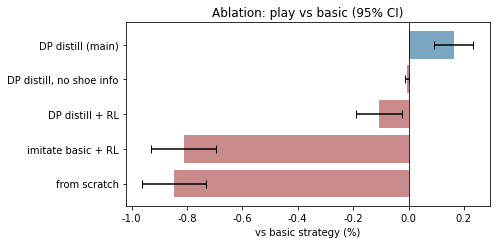

In [16]:
if HAS_PLT:
    names = list(models)
    vals = np.array([r["mean_diff"] for r in abl_res]) * 100
    err = np.array([[r["mean_diff"] - r["ci95"][0], r["ci95"][1] - r["mean_diff"]] for r in abl_res]).T * 100
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.barh(range(len(vals)), vals, xerr=err, capsize=4,
            color=["#c98b8b" if v < 0 else "#7aa6c2" for v in vals])
    ax.axvline(0, color="k", lw=0.8)
    en = {"從零訓練": "from scratch", "模仿 basic + RL": "imitate basic + RL",
          "DP 蒸餾 + RL 微調": "DP distill + RL", "無牌堆資訊的 DP 蒸餾": "DP distill, no shoe info",
          "DP 蒸餾（主方法）": "DP distill (main)"}
    ax.set_yticks(range(len(vals))); ax.set_yticklabels([L(n, en[n]) for n in names])
    ax.set_xlabel(L("相對 basic strategy（%）", "vs basic strategy (%)"))
    ax.set_title(L("消融實驗：出牌相對 basic（95% CI）", "Ablation: play vs basic (95% CI)"))
    plt.tight_layout(); plt.show()

## 第 9 階段：資金管理（展示 RL 的序列決策）

前面的出牌可以用 DP 精確規劃，下注在「資金無限、期望值最大化」下是單步的完整資訊問題，兩者都不需要 RL。但資金有限、有目標與期限時，最佳下注同時取決於**牌面優勢、目前資金、剩餘局數**，而且現在的下注會改變未來的資金，這才是 RL 適合的序列決策。

**問題**：起始資金 `BANK_START` 單位，`BANK_HORIZON` 局內達到 `BANK_TARGET` 單位即成功；資金低於最小注即破產；每局必須下注（不得超過資金）。目標是最大化成功機率。

**分工**：出牌用蒸餾出牌頭（凍結），第 5 階段的下注頭當作「牌面優勢」預測器，資金管理 DQN 依（資金、剩餘局數、牌面優勢）決定下注。

**評估設計**：
- 下注不影響發牌，所以先錄製「每局的優勢預測與每單位實際結果」，所有策略在**同一段牌序**上比較
- **訓練序列**（DQN 訓練、DP 估計轉移都用它）與**測試序列**（不同 seed，未見過）分開；兩者都評估，差距反映過擬合。所有策略決策時都只看可見資訊，沒有任何策略看得到未來的牌
- **不重疊起點**：每個 episode 使用互不共用的牌局區段，信賴區間才正確
- 報告結局分類（成功／破產／期限到期）、期末資金分布、最大回撤，以及起始資金 × 期限的敏感度網格
- DQN 以最長期限（exploring starts 涵蓋各種資金與剩餘局數）訓練一次、DP 以最長期限求解一次，即可評估整個網格；這同時檢驗 DQN 能否泛化到不同起點與期限

簡化：分牌、加倍的額外下注不受資金限制，因此期末資金可能略低於 0（視為破產）。

In [17]:
from blackjack_rl.bankroll import (BankrollConfig, load_seq, solve_dp, make_dp_policy, load_dqn, make_dqn_policy,
                                   compare_policies, sensitivity_grid, format_comparison, heatmap, BASELINES, REF)
_bets = tuple(int(x) for x in BANK_BETS.split(","))
bank_cfg = BankrollConfig(start=BANK_START, target=BANK_TARGET, horizon=BANK_HORIZON, bets=_bets)
H_MAX = max(BANK_GRID_HORIZONS + [BANK_HORIZON])
bank_train_cfg = BankrollConfig(start=BANK_START, target=BANK_TARGET, horizon=H_MAX, bets=_bets)
src = full[TRAIN_SEEDS[0]]                       # 完整系統：蒸餾出牌頭 + 下注頭
seq_train, seq_test = f"{RUNS}/bank_train.npz", f"{RUNS}/bank_test.npz"
cmds, logs = [], []
for path, n, seed in [(seq_train, BANK_TRAIN_ROUNDS, 11), (seq_test, BANK_TEST_ROUNDS, 22)]:
    if not os.path.exists(path):
        cmds.append(["blackjack_rl.bankroll", "record", "--decks", DECKS, "--play", src, "--edge", src,
                     "--rounds", n, "--seed", seed, "--out", path])
        logs.append(f"{LOGS}/stage9_record_{os.path.basename(path)[:-4]}.txt")
if cmds:
    print("錄製序列中（每局都要執行出牌頭與下注頭；1000 萬局約需 1 小時以上）…")
    run_commands(cmds, logs, parallel=True)
for path in (seq_train, seq_test):
    d = load_seq(path)
    print(f"{path}：{len(d['R']):,} 局，每單位平均結果 {d['R'].mean() * 100:+.3f}%，"
          f"預測優勢為正的局 {np.mean(d['V'] > 0):.1%}，期限 {BANK_HORIZON} 時可得不重疊 episode "
          f"{(len(d['R']) - 1) // BANK_HORIZON:,} 個")

錄製序列中（每局都要執行出牌頭與下注頭；1000 萬局約需 1 小時以上）…
完成 2 個指令（118.7 分鐘）
runs/bank_train.npz：3,000,000 局，每單位平均結果 -0.181%，預測優勢為正的局 39.2%，期限 500 時可得不重疊 episode 5,999 個
runs/bank_test.npz：10,000,000 局，每單位平均結果 -0.155%，預測優勢為正的局 39.2%，期限 500 時可得不重疊 episode 19,999 個


In [18]:
# DP（上限參照）：以最長期限求解一次，策略依剩餘局數索引，可用於網格中所有較短的期限
dp_path = f"{RUNS}/bank_dp_h{H_MAX}.npz"
if not os.path.exists(dp_path):
    np.savez_compressed(dp_path, **solve_dp(load_seq(seq_train), bank_train_cfg))
bank_dp = dict(np.load(dp_path))

# 資金管理 DQN：以最長期限訓練（Double DQN、dueling、exploring starts）
bank_model = f"{RUNS}/bank_dqn_h{H_MAX}/model.pt"
if not os.path.exists(bank_model):
    run_commands([["blackjack_rl.bankroll", "train", "--seq", seq_train, "--eval-seq", seq_test,
                   "--start", BANK_START, "--target", BANK_TARGET, "--horizon", H_MAX,
                   "--bets", BANK_BETS, "--episodes", BANK_EPISODES, "--out", os.path.dirname(bank_model)]],
                 [f"{LOGS}/stage9_train.txt"])
tail(f"{LOGS}/stage9_train.txt", 3)
_m, _c = load_dqn(bank_model)
bank_pols = {**BASELINES, "DP 最佳解（上限參照）": make_dp_policy(bank_dp), "資金管理 DQN": make_dqn_policy(_m, _c)}

DP 求解完成（2s）：12 個優勢等級、18 種單局結果，模型預估成功機率 54.00%
完成 1 個指令（38.3 分鐘）
  episode 980,021  eps 0.020  驗證成功率 49.48%（2258s）
  episode 990,007  eps 0.020  驗證成功率 48.70%（2277s）
  episode 1,000,004  eps 0.020  驗證成功率 49.00%（2295s）


In [19]:
bank_eval = cached(f"{RES}/stage9_bankroll.json", lambda: {
    "test": compare_policies(bank_pols, load_seq(seq_test), bank_cfg, BANK_EVAL_EPISODES),
    "train": compare_policies(bank_pols, load_seq(seq_train), bank_cfg, BANK_EVAL_EPISODES)})
print("==== 測試序列（未見過的牌局，泛化表現）====")
print(format_comparison(bank_eval["test"]))
print("\n==== 訓練序列（DQN 與 DP 都從這裡學習）====")
print(format_comparison(bank_eval["train"]))

# 訓練與測試序列的差距：兩條序列本身的難度不同（抽樣差異），以不學習的「目前規則」為對照扣除
base_gap = bank_eval["train"][REF]["success"] - bank_eval["test"][REF]["success"]
print(f"\n==== 訓練 − 測試（成功機率）；以不學習的目前規則（{base_gap * 100:+.2f} pt）作為序列難度差的對照 ====")
for n in bank_pols:
    g = bank_eval["train"][n]["success"] - bank_eval["test"][n]["success"]
    print(f"{n:<30}{g * 100:+6.2f} pt   扣除序列差後 {(g - base_gap) * 100:+6.2f} pt")
print("扣除後明顯為正者，代表在訓練序列上的表現有過擬合成分。")

res_t = bank_eval["test"]
dq, gr, dpr = res_t["資金管理 DQN"], res_t[REF], res_t["DP 最佳解（上限參照）"]
gap = dpr["success"] - gr["success"]
print("\n資金管理 DQN（測試序列）："
      + ("顯著優於目前規則" if dq["diff_ci95"][0] > 0 else "無法確認優於目前規則")
      + (f"，達到 DP 改善量的 {(dq['success'] - gr['success']) / gap:.0%}" if gap > 0 else ""))

已計算並存檔：results/stage9_bankroll.json（0.2 分鐘）
==== 測試序列（未見過的牌局，泛化表現）====
500 局內從 50 到 100；19,999 個 episode（不重疊起點，所有策略同牌序）
策略                                  成功      破產      到期   成功 95% CI          相對目前規則（配對）
固定最小注                            4.78%   5.31%  89.91%   [4.48%, 5.08%]   -42.44 pt [-43.17, -41.72]
期望值為正下最大注（目前規則）                 47.22%  52.78%   0.00%   [46.53%, 47.91%]   +0.00 pt [+0.00, +0.00]
Kelly 比例下注                       4.83%   5.31%  89.86%   [4.53%, 5.12%]   -42.40 pt [-43.13, -41.67]
Bold play（下注到達標所需）              48.76%  51.24%   0.00%   [48.07%, 49.46%]   +1.54 pt [+0.77, +2.31]
DP 最佳解（上限參照）                    52.76%  47.19%   0.05%   [52.07%, 53.45%]   +5.54 pt [+4.66, +6.42]
資金管理 DQN                        48.35%  51.27%   0.38%   [47.66%, 49.05%]   +1.13 pt [+0.31, +1.95]

策略                                       期末資金 5/25/50/75/95 分位      平均   最大回撤 平均/中位/95%（單位）  比例平均/95%
固定最小注                             0.5   31.5   49.0   66.5   96.0    49.2     30.5 /  28

In [20]:
bank_grid = cached(f"{RES}/stage9_grid.json", lambda: sensitivity_grid(
    bank_pols, load_seq(seq_test), bank_cfg, BANK_GRID_STARTS, BANK_GRID_HORIZONS, BANK_EVAL_EPISODES))
print(f"敏感度網格（目標 {BANK_TARGET}，測試序列）：成功機率；括號內為相對目前規則（配對）")
for n in ["資金管理 DQN", "DP 最佳解（上限參照）", "Bold play（下注到達標所需）", REF]:
    print(f"\n[{n}]")
    print("  起始資金＼期限" + "".join(f"{h:>22}" for h in BANK_GRID_HORIZONS))
    for s0 in BANK_GRID_STARTS:
        row = ""
        for h in BANK_GRID_HORIZONS:
            r = bank_grid["grid"][f"{float(s0)}|{h}"][n]
            row += f"{r['success']:>10.1%}（{r['diff_vs_ref'] * 100:+5.1f} pt）"
        print(f"  {s0:>12}  {row}")

已計算並存檔：results/stage9_grid.json（1.1 分鐘）
敏感度網格（目標 100，測試序列）：成功機率；括號內為相對目前規則（配對）

[資金管理 DQN]
  起始資金＼期限                   250                   500                  1000
            25       22.1%（ -2.5 pt）     23.9%（ -0.6 pt）     24.2%（ -0.3 pt）
            50       46.1%（ -1.1 pt）     48.4%（ +1.1 pt）     49.2%（ +1.5 pt）
            75       70.9%（ +1.3 pt）     72.8%（ +3.4 pt）     73.5%（ +4.1 pt）

[DP 最佳解（上限參照）]
  起始資金＼期限                   250                   500                  1000
            25       27.5%（ +2.9 pt）     27.7%（ +3.3 pt）     28.0%（ +3.4 pt）
            50       52.3%（ +5.2 pt）     52.8%（ +5.5 pt）     53.7%（ +6.1 pt）
            75       76.5%（ +6.9 pt）     76.8%（ +7.3 pt）     77.5%（ +8.0 pt）

[Bold play（下注到達標所需）]
  起始資金＼期限                   250                   500                  1000
            25       25.6%（ +1.0 pt）     25.4%（ +1.0 pt）     25.4%（ +0.9 pt）
            50       48.9%（ +1.7 pt）     48.8%（ +1.5 pt）     49.2%（ +1.5 pt）
            75       72.8%（

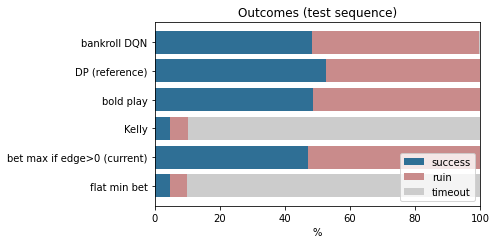

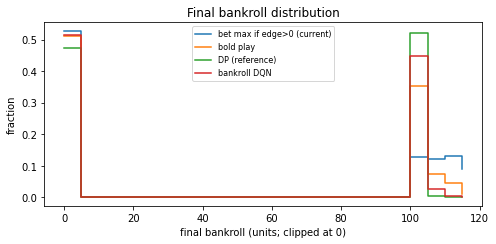

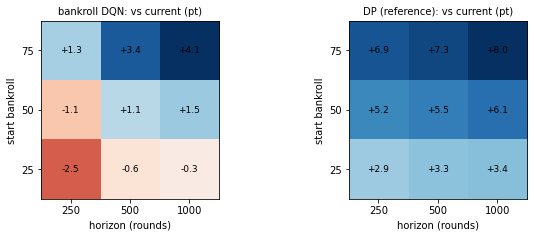

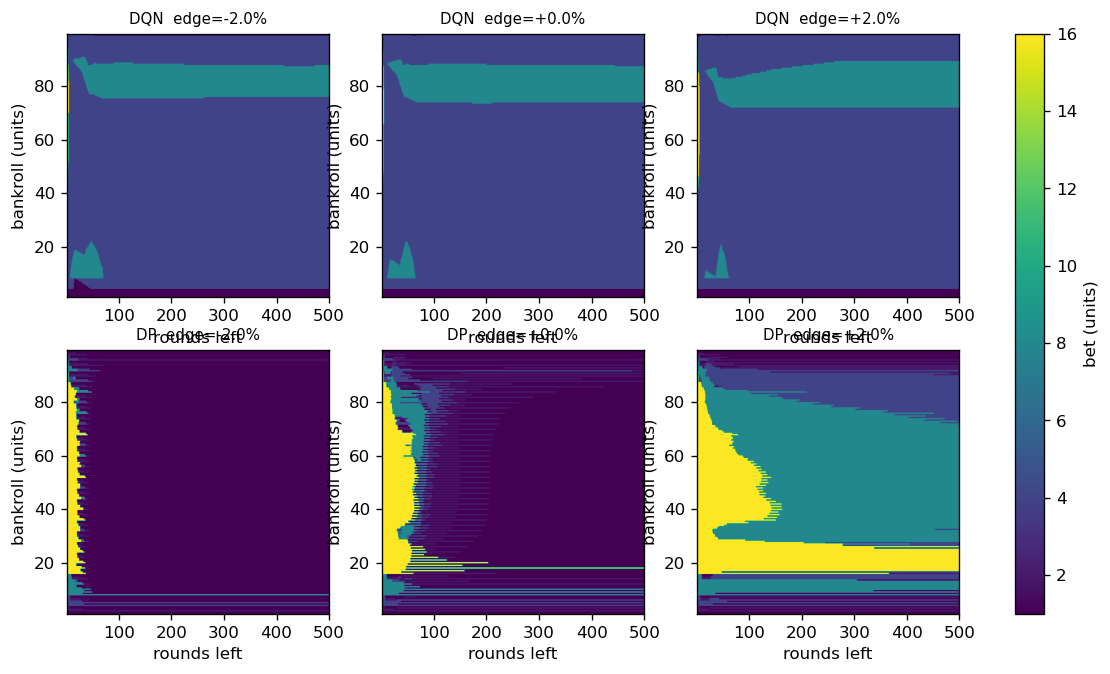

In [21]:
if HAS_PLT:
    en = {"固定最小注": "flat min bet", REF: "bet max if edge>0 (current)", "Kelly 比例下注": "Kelly",
          "Bold play（下注到達標所需）": "bold play", "DP 最佳解（上限參照）": "DP (reference)",
          "資金管理 DQN": "bankroll DQN"}
    names = [n for n in res_t if not n.startswith("_")]
    # 1. 結局分類
    fig, ax = plt.subplots(figsize=(7, 3.5))
    left = np.zeros(len(names))
    for key, col, lab in [("success", "#2f6f95", L("成功", "success")), ("ruin", "#c98b8b", L("破產", "ruin")),
                          ("timeout", "#cccccc", L("期限到期", "timeout"))]:
        v = np.array([res_t[n][key] for n in names]) * 100
        ax.barh(range(len(names)), v, left=left, color=col, label=lab); left += v
    ax.set_yticks(range(len(names))); ax.set_yticklabels([L(n, en[n]) for n in names])
    ax.set_xlabel("%"); ax.set_title(L("結局分類（測試序列）", "Outcomes (test sequence)")); ax.legend(loc="lower right")
    plt.tight_layout(); plt.show()
    # 2. 期末資金分布
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for n in [REF, "Bold play（下注到達標所需）", "DP 最佳解（上限參照）", "資金管理 DQN"]:
        cnt, edges = res_t[n]["final_hist"]
        ax.step(edges[:-1], np.array(cnt) / sum(cnt), where="post", label=L(n, en[n]))
    ax.set_xlabel(L("期末資金（單位；0 以下截斷為 0）", "final bankroll (units; clipped at 0)"))
    ax.set_ylabel(L("比例", "fraction")); ax.set_title(L("期末資金分布", "Final bankroll distribution")); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()
    # 3. 敏感度網格：DQN 與 DP 相對目前規則的改善
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
    for ax, n in zip(axes, ["資金管理 DQN", "DP 最佳解（上限參照）"]):
        M = np.array([[bank_grid["grid"][f"{float(s0)}|{h}"][n]["diff_vs_ref"] * 100 for h in BANK_GRID_HORIZONS]
                      for s0 in BANK_GRID_STARTS])
        im = ax.imshow(M, cmap="RdBu", vmin=-np.abs(M).max(), vmax=np.abs(M).max(), origin="lower")
        for (a, b), v in np.ndenumerate(M):
            ax.text(b, a, f"{v:+.1f}", ha="center", va="center", fontsize=9)
        ax.set_xticks(range(len(BANK_GRID_HORIZONS))); ax.set_xticklabels(BANK_GRID_HORIZONS)
        ax.set_yticks(range(len(BANK_GRID_STARTS))); ax.set_yticklabels(BANK_GRID_STARTS)
        ax.set_xlabel(L("期限（局）", "horizon (rounds)")); ax.set_ylabel(L("起始資金", "start bankroll"))
        ax.set_title(L(f"{n}：相對目前規則（pt）", f"{en[n]}: vs current (pt)"), fontsize=10)
    plt.tight_layout(); plt.show()

# 4. 下注熱圖：橫軸剩餘局數、縱軸資金、顏色為下注；三欄為不同牌面優勢
from IPython.display import Image, display
hm = heatmap({"DQN": make_dqn_policy(_m, _c), "DP": make_dp_policy(bank_dp)}, bank_cfg, [-0.02, 0.0, 0.02],
             f"{RES}/stage9_heatmap.png")
display(Image(hm))

## 結果摘要

In [22]:
print("=" * 60)
print(f"basic strategy 期望值          ：{fmt_pct(basic['ev'], basic['ci95'])}")
print(f"DP 出牌相對 basic（上限參照）  ：{fmt_pct(dp_ref['mean_diff'], dp_ref['ci95'])}（{len(TEST_SEEDS)} 個 seed 合併）")
print(f"DP 蒸餾 DQN 相對 basic          ：{fmt_pct(overall['mean'], overall['ci95'])}"
      f"（{overall['n']} 次合併，達 DP 的 {overall['mean'] / dp_ref['mean_diff']:.0%}）")
print(f"完整系統每單位下注 EV            ：{summary['dqn+head']['ev'] * 100:+.3f}%"
      f"（平均下注 {summary['dqn+head']['bet']:.2f}）")
print(f"完整系統每局報酬                ：{fmt_pct(summary['dqn+head']['round']['mean'], summary['dqn+head']['round']['ci95'])}")
if "bank_eval" in globals():
    t = bank_eval["test"]
    print(f"資金管理（{BANK_HORIZON} 局內 {BANK_START}→{BANK_TARGET}，測試序列）成功／破產："
          f"目前規則 {t[REF]['success']:.1%}／{t[REF]['ruin']:.1%}、"
          f"DQN {t['資金管理 DQN']['success']:.1%}／{t['資金管理 DQN']['ruin']:.1%}、"
          f"DP {t['DP 最佳解（上限參照）']['success']:.1%}／{t['DP 最佳解（上限參照）']['ruin']:.1%}")
print("=" * 60)

basic strategy 期望值          ：-0.394% [-0.552%, -0.236%]
DP 出牌相對 basic（上限參照）  ：+0.160% [+0.137%, +0.183%]（3 個 seed 合併）
DP 蒸餾 DQN 相對 basic          ：+0.151% [+0.138%, +0.163%]（9 次合併，達 DP 的 94%）
完整系統每單位下注 EV            ：+0.561%（平均下注 3.95）
完整系統每局報酬                ：+2.215% [+1.822%, +2.607%]
資金管理（500 局內 50→100，測試序列）成功／破產：目前規則 47.2%／52.8%、DQN 48.4%／51.3%、DP 52.8%／47.2%
